# Homework 1: NAIP, NDVI, and vegetation cover

## 1. Setup

In [30]:
from pathlib import Path
from contextlib import ExitStack
import urllib.request

import fiona
import geopandas as gpd
import numpy as np
import planetary_computer as pc
import pystac_client
import rasterio as rio
from matplotlib import pyplot as plt
from rasterio.mask import mask
from rasterio.merge import merge
from rasterio.windows import Window
from shapely.geometry import box, mapping, shape

In [45]:
project_dir = Path.cwd()
if (project_dir / "ai-urban-sustainability").is_dir():
    project_dir = project_dir / "ai-urban-sustainability"
lab_dir = project_dir / "lab3-raster-data-manipulation"
if project_dir.name == "lab3-raster-data-manipulation":
    lab_dir = project_dir
    project_dir = project_dir.parent

data_dir = lab_dir / "data"
shpfile = data_dir / "city_limit_4326.shp"
naip_dir = lab_dir / "cir-naip"
output_dir = project_dir / "homework1-output"
output_dir.mkdir(parents=True, exist_ok=True)

startDate = "2018-06-01"
endDate = "2018-09-30"
MAX_TILES = None
DOWNLOAD_MISSING = True
NDVI_THRESHOLD = 0
TILE_SIZE = 2000
# Set this to the census-tract file for the same city as shpfile.
tract_file = data_dir / "tl_2010_06075_tract10.shp"

mosaic_file = output_dir / "mosaicked-naip.tif"
masked_file = output_dir / "masked-naip.tif"
ndvi_file = output_dir / "ndvi.tif"
vegetation_file = output_dir / "vegetation.tif"

## 2. Study area and NAIP download

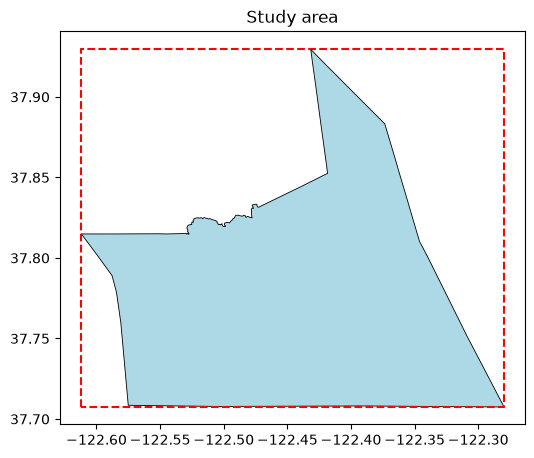

In [4]:
city = gpd.read_file(shpfile).to_crs("EPSG:4326")
city_parts = list(city.geometry)
left, bottom, right, top = city.total_bounds
area_of_interest = mapping(box(left, bottom, right, top))

fig, ax = plt.subplots(figsize=(6, 6))
city.plot(ax=ax, color="lightblue", edgecolor="black", linewidth=0.6)
gpd.GeoSeries([box(left, bottom, right, top)], crs=city.crs).boundary.plot(
    ax=ax, color="red", linestyle="--"
)
ax.set_title("Study area")
plt.show()

In [33]:
def naip_downloader(shpfile, outfolder, startDate, endDate,
                    skip_existing=True, max_tiles=None):
    boundary = gpd.read_file(shpfile).to_crs("EPSG:4326")
    city_parts = list(boundary.geometry)
    area_of_interest = mapping(box(*boundary.total_bounds))
    outfolder = Path(outfolder)
    outfolder.mkdir(parents=True, exist_ok=True)

    catalog = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=pc.sign_inplace,
    )
    items_tiles = catalog.search(
        collections=["naip"],
        intersects=area_of_interest,
        datetime=f"{startDate}/{endDate}",
    ).item_collection()
    keep = [item for item in items_tiles
            if any(shape(item.geometry).intersects(part) for part in city_parts)]
    if max_tiles is not None:
        keep = keep[:max_tiles]
    if not keep:
        raise ValueError("No NAIP tiles found; check the study area and date range.")
    print(f"{len(keep)} tiles intersect the study area")

    downloaded = []
    for n, item in enumerate(keep, start=1):
        outfilename = outfolder / f"{item.id}.tif"
        if skip_existing and outfilename.exists():
            print(f"[{n}/{len(keep)}] {item.id} — already on disk")
        else:
            print(f"[{n}/{len(keep)}] downloading {item.id}")
            temporary_file = outfilename.with_suffix(".tif.part")
            urllib.request.urlretrieve(pc.sign(item.assets["image"].href), temporary_file)
            temporary_file.replace(outfilename)
        downloaded.append(outfilename)
    return downloaded

In [34]:
if DOWNLOAD_MISSING:
    tiles = naip_downloader(shpfile, naip_dir, startDate, endDate,
                            max_tiles=MAX_TILES)
else:
    # Local-only mode does not verify complete city coverage or acquisition dates.
    tiles = sorted(naip_dir.glob("*.tif"))
    if MAX_TILES is not None:
        tiles = tiles[:MAX_TILES]
    print("Using local tiles; coverage and dates have not been verified.")
if not tiles:
    raise FileNotFoundError(f"No NAIP tiles found in {naip_dir}")
print(f"{len(tiles)} tiles available")

17 tiles intersect the study area
[1/17] ca_m_3712221_nw_10_060_20180804_20190210 — already on disk
[2/17] ca_m_3712221_ne_10_060_20180804_20190210 — already on disk
[3/17] ca_m_3712220_ne_10_060_20180804_20190210 — already on disk
[4/17] ca_m_3712213_sw_10_060_20180804_20190209 — already on disk
[5/17] ca_m_3712213_se_10_060_20180804_20190209 — already on disk
[6/17] ca_m_3712213_nw_10_060_20180804_20190209 — already on disk
[7/17] ca_m_3712213_ne_10_060_20180804_20190209 — already on disk
[8/17] ca_m_3712212_se_10_060_20180804_20190209 — already on disk
[9/17] ca_m_3712212_nw_10_060_20180804_20190210 — already on disk
[10/17] ca_m_3712212_ne_10_060_20180804_20190210 — already on disk
[11/17] ca_m_3712222_nw_10_060_20180723_20190209 — already on disk
[12/17] ca_m_3712222_ne_10_060_20180723_20190210 — already on disk
[13/17] ca_m_3712214_sw_10_060_20180723_20190209 — already on disk
[14/17] ca_m_3712214_se_10_060_20180723_20190209 — already on disk
[15/17] ca_m_3712214_nw_10_060_201807

/opt/anaconda3/envs/geoai/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


## 3. Raster metadata and imagery

In [35]:
naip_file = tiles[0]
with rio.open(naip_file) as dataset:
    print("File:", naip_file.name)
    print("CRS:", dataset.crs)
    print("Size:", dataset.width, "x", dataset.height)
    print("Bands:", dataset.count, dataset.dtypes)
    print("Resolution:", dataset.res)
    print("Bounds:", dataset.bounds)
    naip_meta = dataset.meta.copy()
naip_meta

File: ca_m_3712221_nw_10_060_20180804_20190210.tif
CRS: EPSG:26910
Size: 9760 x 12120
Bands: 4 ('uint8', 'uint8', 'uint8', 'uint8')
Resolution: (0.6, 0.6)
Bounds: BoundingBox(left=543894.0, bottom=4171110.0, right=549750.0, top=4178382.0)


{'driver': 'GTiff',
 'dtype': 'uint8',
 'nodata': None,
 'width': 9760,
 'height': 12120,
 'count': 4,
 'crs': CRS.from_wkt('PROJCS["NAD83 / UTM zone 10N",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-123],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","26910"]]'),
 'transform': Affine(0.6, 0.0, 543894.0,
        0.0, -0.6, 4178382.0)}

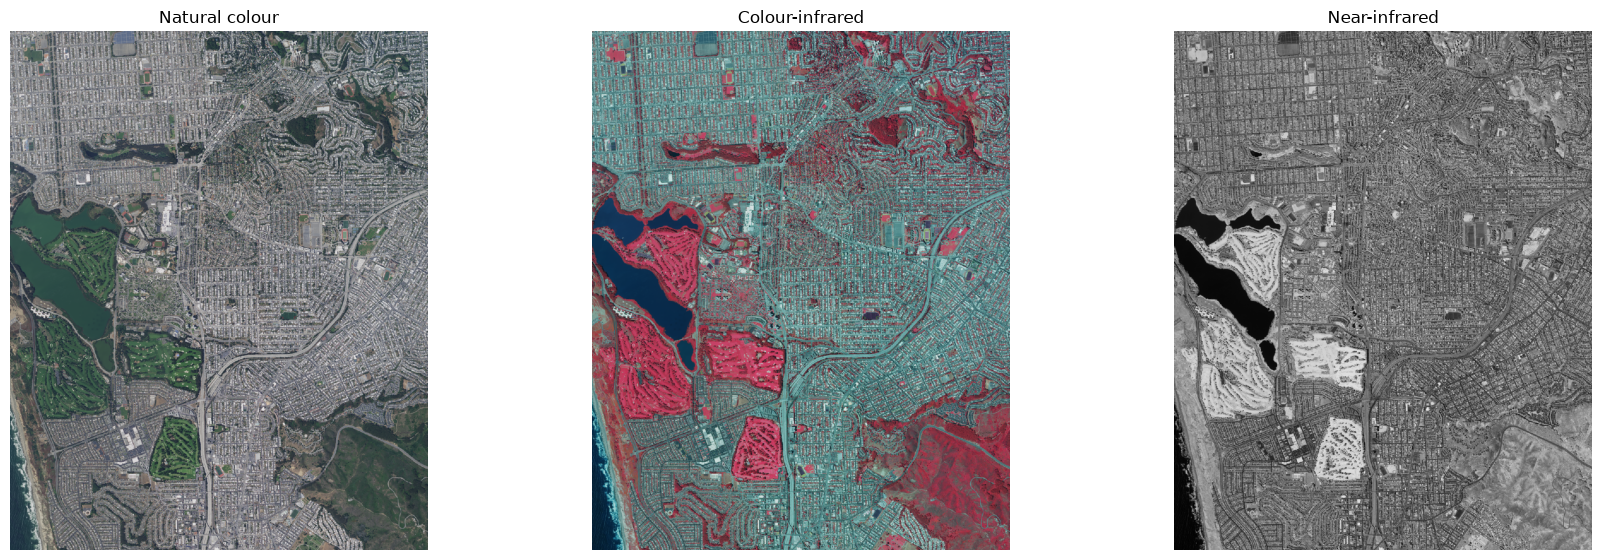

In [36]:
def display_naip_tile(filename, dsfactor=10):
    with rio.open(filename) as raster:
        h = max(1, raster.height // dsfactor)
        w = max(1, raster.width // dsfactor)
        red, green, blue, nir = raster.read([1, 2, 3, 4], out_shape=(4, h, w))
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(np.dstack((red, green, blue)))
    axes[0].set_title("Natural colour")
    axes[1].imshow(np.dstack((nir, red, green)))
    axes[1].set_title("Colour-infrared")
    axes[2].imshow(nir, cmap="gray")
    axes[2].set_title("Near-infrared")
    for ax in axes:
        ax.set_axis_off()
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

display_naip_tile(naip_file)

## 4. NDVI and vegetation for one tile

NDVI minimum, mean, maximum: -0.95238096 -0.022176896928934698 0.7419355


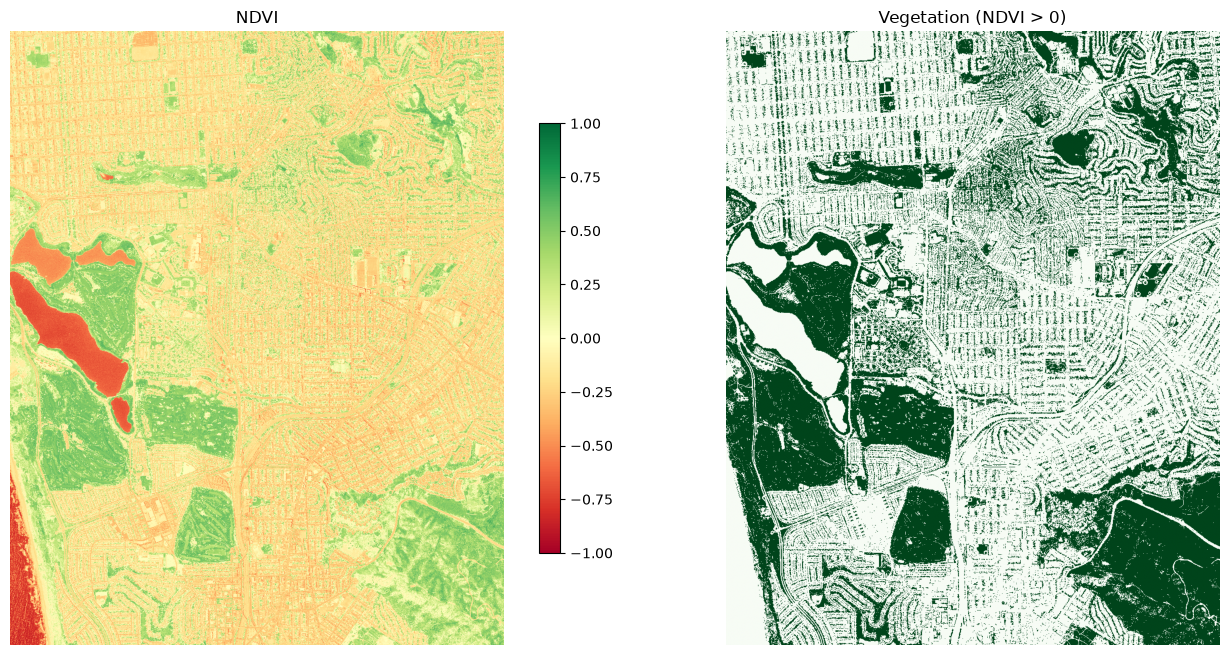

In [37]:
def calculate_ndvi(red, nir):
    red = np.ma.asarray(red, dtype="float32")
    nir = np.ma.asarray(nir, dtype="float32")
    denominator = nir + red
    return np.ma.masked_invalid(
        (nir - red) / np.ma.masked_where(denominator == 0, denominator)
    )

with rio.open(naip_file) as dataset:
    red = dataset.read(1, masked=True)
    nir = dataset.read(4, masked=True)
    ndvi = calculate_ndvi(red, nir)
    veg = np.ma.array((ndvi > NDVI_THRESHOLD).astype("uint8"), mask=ndvi.mask)
    out_meta = dataset.meta.copy()

out_meta.update(count=1, dtype="uint8", nodata=255, compress="lzw")
with rio.open(output_dir / "single-tile-vegetation.tif", "w", **out_meta) as dest:
    dest.write(veg.filled(255), 1)

print("NDVI minimum, mean, maximum:", ndvi.min(), ndvi.mean(), ndvi.max())
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
im = axes[0].imshow(ndvi[::10, ::10], cmap="RdYlGn", vmin=-1, vmax=1)
axes[0].set_title("NDVI")
plt.colorbar(im, ax=axes[0], shrink=0.7)
axes[1].imshow(veg[::10, ::10], cmap="Greens", vmin=0, vmax=1)
axes[1].set_title(f"Vegetation (NDVI > {NDVI_THRESHOLD})")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
del red, nir, ndvi, veg

## 5. Mosaic and clip to the city

In [38]:
def mosaic_rasters(paths, destination, nodata=None):
    with ExitStack() as stack:
        sources = [stack.enter_context(rio.open(path)) for path in paths]
        if not sources:
            raise ValueError("No rasters supplied for mosaicking.")
        if any(src.crs != sources[0].crs for src in sources):
            raise ValueError("Reproject the input rasters to a common CRS first.")
        merge(sources, dst_path=str(destination), nodata=nodata,
              dst_kwds={"compress": "lzw", "BIGTIFF": "YES"})

mosaic_rasters(tiles, mosaic_file, nodata=0)
print(mosaic_file)

/Users/freddie/Projects/HailMary/ai-urban-sustainability/homework1-output/mosaicked-naip.tif


In [39]:
with rio.open(mosaic_file) as src:
    city_projected = city.to_crs(src.crs)
    shapes = [mapping(geom) for geom in city_projected.geometry]
    out_image, out_transform = mask(src, shapes, crop=True, nodata=0)
    out_meta = src.meta.copy()
    out_meta.update(
        height=out_image.shape[1], width=out_image.shape[2],
        transform=out_transform, nodata=0, compress="lzw", BIGTIFF="YES",
    )
with rio.open(masked_file, "w", **out_meta) as dest:
    dest.write(out_image)
del out_image
print(masked_file)

/opt/anaconda3/envs/geoai/lib/python3.14/site-packages/rasterio/mask.py:191: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  out_image = dataset.read(


/Users/freddie/Projects/HailMary/ai-urban-sustainability/homework1-output/masked-naip.tif


## 6. Split the raster and calculate NDVI and vegetation

In [40]:
naip_tile_dir = output_dir / "naip-tiles"
ndvi_tile_dir = output_dir / "ndvi-tiles"
veg_tile_dir = output_dir / "veg-tiles"
for folder in (naip_tile_dir, ndvi_tile_dir, veg_tile_dir):
    folder.mkdir(parents=True, exist_ok=True)

split_tiles = []
with rio.open(masked_file) as src:
    for row_start in range(0, src.height, TILE_SIZE):
        for col_start in range(0, src.width, TILE_SIZE):
            window = Window(col_start, row_start,
                            min(TILE_SIZE, src.width - col_start),
                            min(TILE_SIZE, src.height - row_start))
            tilename = naip_tile_dir / f"row{row_start // TILE_SIZE}-col{col_start // TILE_SIZE}.tif"
            out_meta = src.meta.copy()
            out_meta.update(height=int(window.height), width=int(window.width),
                            transform=src.window_transform(window), compress="lzw")
            with rio.open(tilename, "w", **out_meta) as dest:
                dest.write(src.read(window=window))
            split_tiles.append(tilename)
print(f"Created {len(split_tiles)} tiles")

Created 525 tiles


In [41]:
ndvi_tiles, veg_tiles = [], []
for tiffile in split_tiles:
    with rio.open(tiffile) as dataset:
        # Native NAIP order: red=1, green=2, blue=3, NIR=4.
        ndvi = calculate_ndvi(dataset.read(1, masked=True), dataset.read(4, masked=True))
        veg = np.ma.array((ndvi > NDVI_THRESHOLD).astype("uint8"), mask=ndvi.mask)
        out_meta = dataset.meta.copy()

    ndvi_path = ndvi_tile_dir / tiffile.name
    out_meta.update(count=1, dtype="float32", nodata=-9999, compress="lzw")
    with rio.open(ndvi_path, "w", **out_meta) as dest:
        dest.write(ndvi.filled(-9999), 1)
    ndvi_tiles.append(ndvi_path)

    veg_path = veg_tile_dir / tiffile.name
    out_meta.update(dtype="uint8", nodata=255)
    with rio.open(veg_path, "w", **out_meta) as dest:
        dest.write(veg.filled(255), 1)
    veg_tiles.append(veg_path)

mosaic_rasters(ndvi_tiles, ndvi_file, nodata=-9999)
mosaic_rasters(veg_tiles, vegetation_file, nodata=255)

/var/folders/bv/lv4ky9sd01v85j37qqrwqtbw0000gn/T/ipykernel_12408/247943142.py:5: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  ndvi = calculate_ndvi(dataset.read(1, masked=True), dataset.read(4, masked=True))


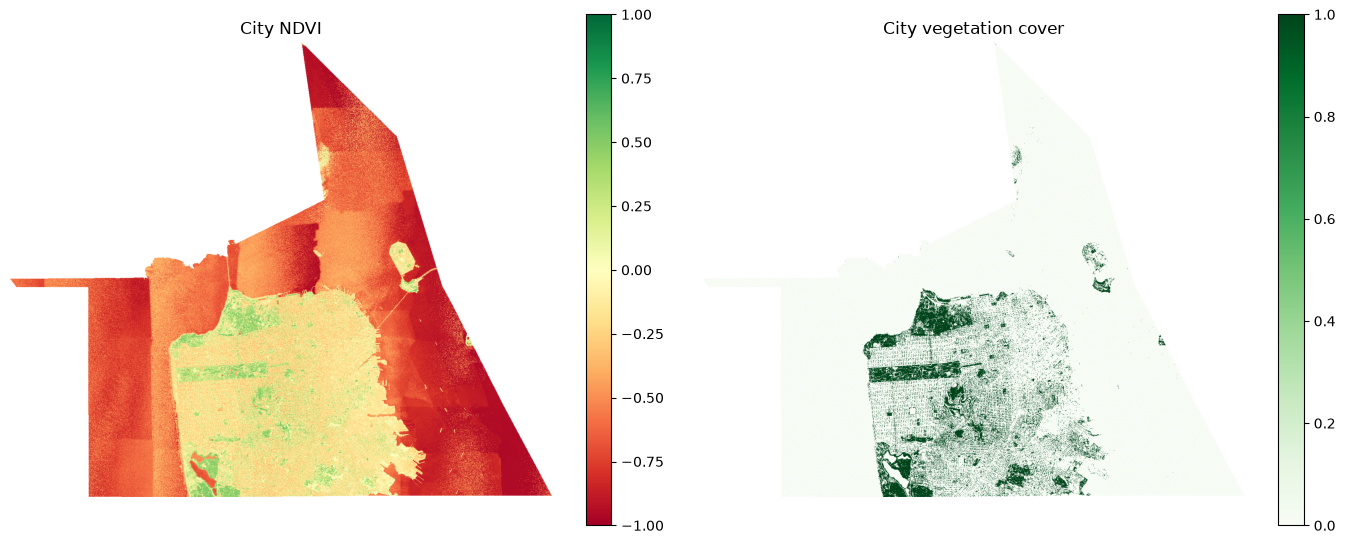

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, path, title, cmap, vmin, vmax in [
    (axes[0], ndvi_file, "City NDVI", "RdYlGn", -1, 1),
    (axes[1], vegetation_file, "City vegetation cover", "Greens", 0, 1),
]:
    with rio.open(path) as src:
        factor = max(1, int(np.ceil(max(src.height, src.width) / 1500)))
        preview = src.read(1, masked=True,
                           out_shape=(max(1, src.height // factor), max(1, src.width // factor)))
    im = ax.imshow(preview, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_axis_off()
    plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 7. Census-tract NDVI and vegetation cover

In [46]:
if not tract_file.exists():
    raise FileNotFoundError(
        f"Set tract_file in Setup to a census-tract file for the study city: {tract_file}. "
        "The San Francisco tracts in data.zip do not match the California imagery."
    )
tracts = gpd.read_file(tract_file)
with rio.open(masked_file) as src:
    tracts = tracts.to_crs(src.crs)
    study_area = city.to_crs(src.crs).geometry.unary_union
    tracts = tracts.loc[tracts.intersects(study_area)].copy()
    if tracts.empty:
        raise ValueError("The census tracts do not overlap the study area.")
    tracts.geometry = tracts.geometry.intersection(study_area)
    means, percentages, valid_counts = [], [], []
    for geom in tracts.geometry:
        try:
            bands, _ = mask(src, [mapping(geom)], indexes=[1, 4],
                            crop=True, filled=False)
        except ValueError:
            means.append(np.nan)
            percentages.append(np.nan)
            valid_counts.append(0)
            continue
        ndvi = calculate_ndvi(bands[0], bands[1])
        count = int(ndvi.count())
        means.append(float(ndvi.mean()) if count else np.nan)
        percentages.append(float((ndvi > NDVI_THRESHOLD).sum() / count * 100)
                           if count else np.nan)
        valid_counts.append(count)

tracts["ndvi_mean"] = means
tracts["veg_pct"] = percentages
tracts["valid_px"] = valid_counts
tracts.to_file(output_dir / "census-tract-vegetation.gpkg", driver="GPKG")
tracts.drop(columns="geometry").to_csv(output_dir / "census-tract-vegetation.csv", index=False)
tracts[["ndvi_mean", "veg_pct", "valid_px"]].head()

/var/folders/bv/lv4ky9sd01v85j37qqrwqtbw0000gn/T/ipykernel_12408/40847775.py:9: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  study_area = city.to_crs(src.crs).geometry.unary_union
/opt/anaconda3/envs/geoai/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geoai/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)
/opt/anaconda3/envs/geoai/lib/python3.14/site-packages/rasterio/mask.py:191: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  out_image = dataset.read(
/opt/anaconda3/envs/geoai/lib/python3.14/site-packages/rasterio/mask.py:191: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. A

,ndvi_mean,veg_pct,valid_px
0,-0.135334,17.406750,1028285
1,-0.078334,25.637583,857967
2,-0.105647,20.377246,682472
3,-0.061321,25.689406,1023998
4,-0.135261,13.178895,439225


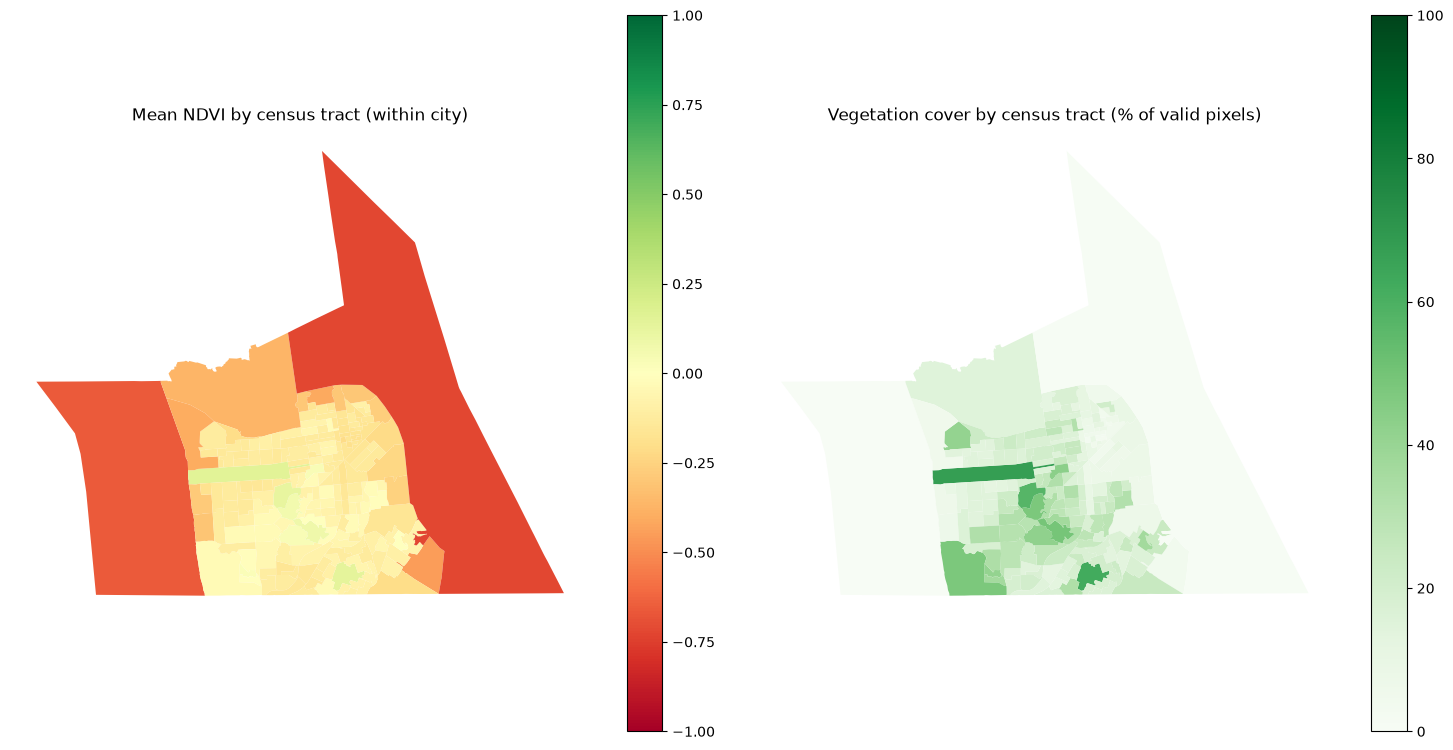

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
tracts.plot(column="ndvi_mean", ax=axes[0], cmap="RdYlGn", vmin=-1, vmax=1,
            legend=True, missing_kwds={"color": "lightgray"})
axes[0].set_title("Mean NDVI by census tract (within city)")
tracts.plot(column="veg_pct", ax=axes[1], cmap="Greens", vmin=0, vmax=100,
            legend=True, missing_kwds={"color": "lightgray"})
axes[1].set_title("Vegetation cover by census tract (% of valid pixels)")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()